# Mortality component attribution

Native analysis for Figures 1 and 4. Each of the 50 hybrid-model members is evaluated under observed weather and the 10 °C cold and 20 °C heat bounds, holding relative humidity constant where temperature changes. Reference mortality uses 16 °C and 50% relative humidity.

[Original analysis notebook](https://github.com/ClimSocAna/sari-weather-mortality/blob/4402a80d3e490ad7964a3be12597043761bebda1/notebooks/01_mortality_component_attribution.ipynb).

The primary hybrid uses 50 members. Comparison ensembles use all of their available members.

In [1]:
from importlib.util import module_from_spec, spec_from_file_location
from pathlib import Path
import sys

cwd = Path.cwd()
repo = next(
    (
        path for path in (cwd, *cwd.parents)
        if (path / "configs" / "training.example.yaml").is_file()
    ),
    None,
)
if repo is None:
    raise FileNotFoundError("Open the notebook from the sari-weather-mortality checkout.")

sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Load helpers from this checkout even if Jupyter cached another notebooks package.
utils_path = repo / "notebooks" / "utils.py"
spec = spec_from_file_location("sari_notebook_utils", utils_path)
notebook_utils = module_from_spec(spec)
spec.loader.exec_module(notebook_utils)

if not hasattr(notebook_utils, "weekly_surveillance"):
    raise ImportError(f"{utils_path} is missing weekly_surveillance. Update to commit d5351c3 or newer.")

daily_index = notebook_utils.daily_index
ensemble = notebook_utils.ensemble
weekly_sum = notebook_utils.weekly_sum
ANALYSIS_PERIOD = notebook_utils.ANALYSIS_PERIOD
DEVICE = notebook_utils.DEVICE
checkpoint_paths = notebook_utils.checkpoint_paths
weekly_surveillance = notebook_utils.weekly_surveillance

from sari_t.inference import InferenceModel
from sari_t.run.checkpoint import load_checkpoint, load_run_config, restore_predictor

## Load models for inspection

Run the next cell to load member `000` for each setup into memory. Inspect `model` for the hybrid predictor or `models[setup]` for another predictor. Set `inspection_member` to another available member index to inspect its weights. The analysis cells evaluate all available members in a separate inference workspace.

In [2]:
inspection_member = 0
setups = ['default', 'no_disease']
checkpoints = {setup: checkpoint_paths(setup) for setup in setups}
models = {
    setup: restore_predictor(load_checkpoint(paths[inspection_member]), device="cpu").eval()
    for setup, paths in checkpoints.items()
}
model = models["default"]
model

MortalityPredictor(
  (effect_model): ExponentialMortalityModel(
    (batch_norm): LazyBatchNorm1d(0, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv1): LazyConv1d(0, 128, kernel_size=(9,), stride=(1,))
    (fc): LinearPos(in_features=128, out_features=30, bias=True)
    (sari_conv): Conv1dPos(15, 30, kernel_size=(10,), stride=(1,), groups=15, bias=False)
    (covid_conv): Conv1dPos(15, 30, kernel_size=(10,), stride=(1,), groups=15, bias=False)
  )
)

## Evaluate temperature counterfactuals

In [3]:
scenarios = {
    "heat_20": {"maximum_c": 20},
    "cold_10": {"minimum_c": 10},
    "band_10_20": {"minimum_c": 10, "maximum_c": 20},
    "cold_0": {"minimum_c": 0},
}

def components(model, result):
    pred = result.predictions
    factual = pred.total_deaths.sum(dim=1)
    sari = pred.sari_deaths.sum(dim=1)
    covid = pred.covid_deaths.sum(dim=1)
    cold = result.scenarios["cold_10"].sum(dim=1)
    extreme = result.scenarios["cold_0"].sum(dim=1)
    return {
        "Observed": model.labels.daily_land.sum(dim=1),
        "Predicted national": factual.sum(dim=(1, 2)),
        "Temperature mortality": pred.temperature_deaths.sum(dim=1),
        "Non-COVID SARI": sari,
        "COVID-19 SARI": covid,
        "Heat above 20 °C": factual - result.scenarios["heat_20"].sum(dim=1),
        "Cold below 10 °C": factual - cold,
        "Cold below 0 °C": factual - extreme,
        "Mild cold (0–10 °C)": extreme - cold,
        "Outside 10–20 °C": factual - result.scenarios["band_10_20"].sum(dim=1),
        "Population": model.data.population.sum(dim=1),
    }

paths = checkpoints["default"]
inputs = load_run_config(paths[0].parents[1] / "config.yaml").data_config
inference_model = InferenceModel.from_checkpoint(
    paths[0], data_config=inputs, period=ANALYSIS_PERIOD, device=DEVICE,
)
members = ensemble(inference_model, paths, components, scenarios=scenarios, keep_members=True)
estimates = {name: values.mean(dim=0) for name, values in members.items()}
torch.testing.assert_close(
    estimates["Mild cold (0–10 °C)"] + estimates["Cold below 0 °C"],
    estimates["Cold below 10 °C"], rtol=1e-4, atol=1e-4,
)
dates = daily_index()

## Prepare respiratory-infection surveillance series

Total SARI incidence is separated into non-COVID SARI and COVID-19-associated SARI. Influenza-specific incidence is retained as an external seasonal reference where available.

In [4]:
incidence = weekly_surveillance(dates)
covid = incidence["COVID-19"]
influenza = incidence["Influenza"]
covid_offset = int(np.flatnonzero(covid.notna())[0])
flu_offset = int(np.flatnonzero(influenza.notna())[0])
covid_incidence = covid.fillna(0).to_numpy()
flu_incidence = influenza.to_numpy()
sari_incidence = incidence["Gesamt"].to_numpy() - covid_incidence

## Manuscript Figure 1: Seasonal attribution

The panels show weekly reconstructed mortality components, national SARI surveillance signals, and heat- and cold-associated mortality alongside weekly mean temperature. Vertical component offsets in the first panel are used only for visual separation.

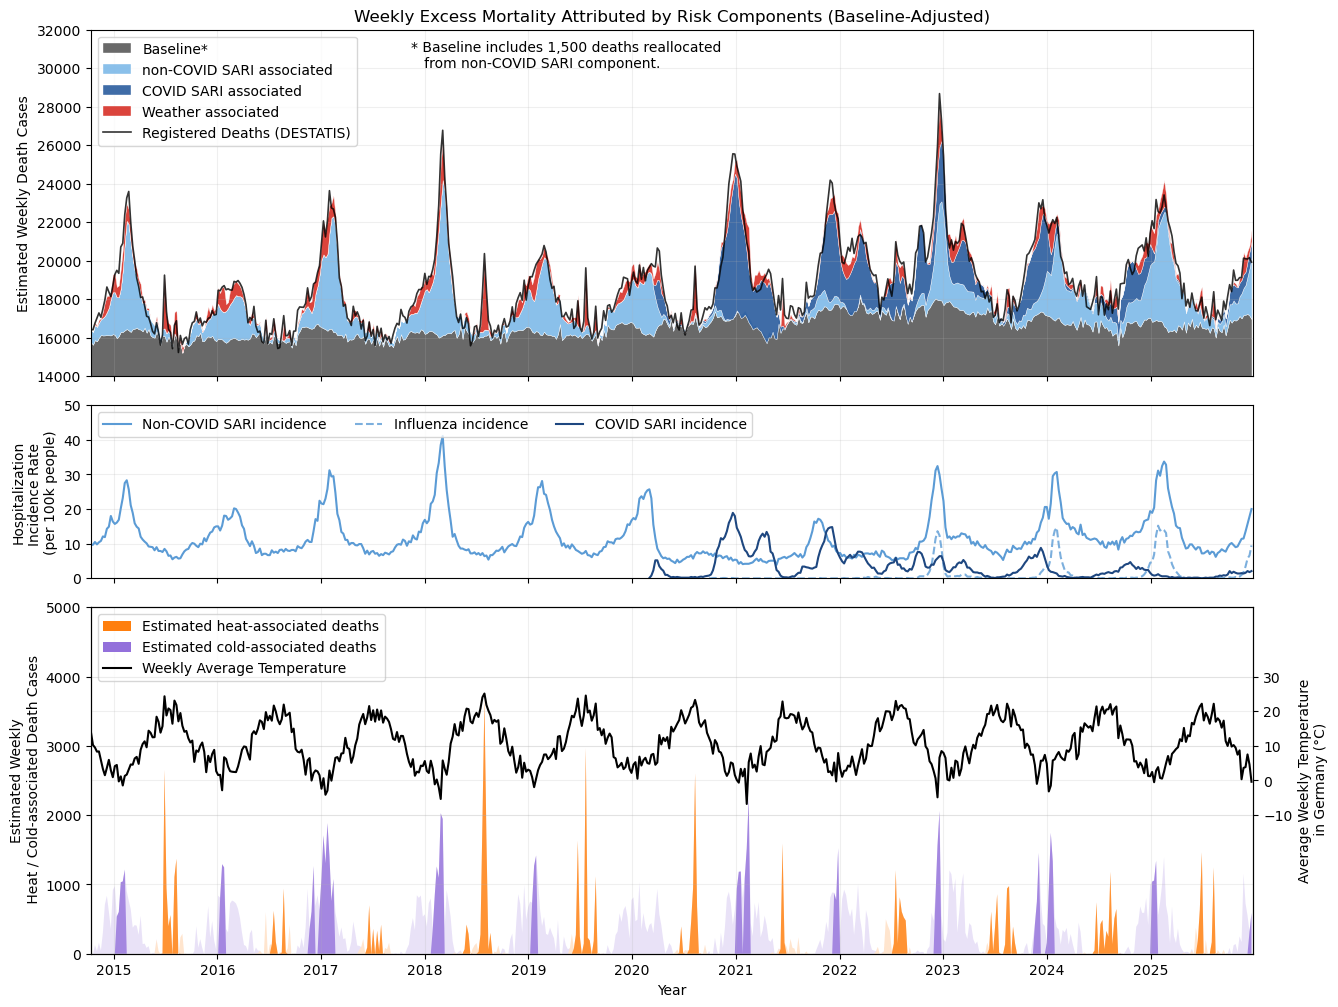

In [5]:
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D

temperature = estimates["Temperature mortality"]
death_temp_model_weekly = weekly_sum(temperature.sum(dim=(1, 2)))
death_sari_weekly = weekly_sum(estimates["Non-COVID SARI"].sum(dim=(1, 2)))
death_covid_weekly = weekly_sum(estimates["COVID-19 SARI"].sum(dim=(1, 2)))
band = temperature - estimates["Outside 10–20 °C"]
death_10_20_weekly = weekly_sum(band.sum(dim=(1, 2)))
val = estimates["Observed"]

c =  [
    '#595959',
    '#7DB9E8',
    '#2A5C9E',
    '#D73027',
]
c2 = ['#5B9BD5', '#5B9BD5', '#1E4780']

data = np.vstack([death_10_20_weekly + 1500, death_sari_weekly - 1500, death_covid_weekly, death_temp_model_weekly - death_10_20_weekly])
fig, ax = plt.subplots(3, 1, figsize=(15, 12), sharex=True,  gridspec_kw=dict(height_ratios=[2, 1, 2], hspace=0.1))
ax[0].stackplot(np.arange(0, data.shape[1]), data,  labels=['Baseline*', 'non-COVID SARI associated', 'COVID SARI associated', 'Weather associated'], alpha=0.9, colors=c, linewidth=0.3, edgecolor='white')
ax[0].grid(True, alpha=0.2)
ax[0].plot(val.reshape(-1,7).sum(1), c='0', lw=1.2, label='Registered Deaths (DESTATIS)', alpha=0.8)
ax[0].legend(loc='upper left')
ax[0].set_title('Weekly Excess Mortality Attributed by Risk Components (Baseline-Adjusted)')

ax[0].text(
    0.275, 0.97,
    '* Baseline includes 1,500 deaths reallocated\n'
    '   from non-COVID SARI component.\n',
    transform=ax[0].transAxes,
    ha='left',
    va='top',
    multialignment='left',
    fontsize=10,
 )

ax[0].set_ylim(14000,32000)
days_cumulative = 80 / 7
ticks = []
for year in range(2015, 2026):
    ticks.append(days_cumulative)
    days_in_year = 366 if (year % 4 == 0 and (year % 100 != 0 or year % 400 == 0)) else 365
    days_cumulative += days_in_year / 7
ax[0].set_xticks(ticks)
ax[0].set_xticklabels([str(y) for y in range(2015, 2026)], fontsize=12)
ax[0].set_xlim(0, len(death_temp_model_weekly))
ax[0].set_ylabel('Estimated Weekly Death Cases')

ax[1].grid(True, alpha=0.2)
ax[1].plot(np.arange(0, data.shape[1]), sari_incidence[:data.shape[1]], color=c2[0], label='Non-COVID SARI incidence', lw=1.5)
ax[1].plot(np.arange(flu_offset, data.shape[1]), flu_incidence[flu_offset:data.shape[1]], color=c2[1], label='Influenza incidence', ls='--', alpha=0.8, lw=1.5)
ax[1].plot(np.arange(covid_offset, data.shape[1]), covid_incidence[covid_offset:data.shape[1]], color=c2[2], label='COVID SARI incidence', lw=1.5)
ax[1].legend(loc='upper left',ncol=3)
ax[1].set_ylim(0, 50)
ax[1].set_ylabel('Hospitalization\nIncidence Rate \n(per 100k people)')

d_heat_weekly = weekly_sum(estimates["Heat above 20 °C"].sum(dim=(1, 2)))
d_cold_weekly = weekly_sum(estimates["Cold below 10 °C"].sum(dim=(1, 2)))

tas_index = inference_model.weather_variables.index('tas')
tas = inference_model.data.model_inputs.temperature[:, tas_index, -len(dates):]
t_week = weekly_sum(tas.mean(dim=0).cpu()) / 7

data = np.vstack([d_heat_weekly, d_cold_weekly])
mask = ((t_week > 0) & (t_week < 20))
mask_mid = mask[1:-1] & mask[:-2] & mask[2:]
result = torch.zeros_like(t_week, dtype=torch.bool)
result[1:-1] = mask_mid
data_extrem = data.copy()
data_extrem[:, result.numpy()] = 0

ax[2].stackplot(np.arange(0, data.shape[1]), data,  linewidth=0, labels=['heat-associated', 'cold-associated'], alpha=0.2, colors=['tab:orange', 'mediumpurple'])
ax[2].stackplot(np.arange(0, data.shape[1]), data_extrem,  linewidth=0, labels=['heat-associated', 'cold-associated'], alpha=0.8, colors=['tab:orange', 'mediumpurple'])
ax[2].grid(True, alpha=0.2)
ax[2].set_ylim(0, 5000)
ax[2].set_ylabel('Estimated Weekly\n Heat / Cold-associated Death Cases')
ax[2].set_xlabel('Year')

twinx = ax[2].twinx()
twinx.plot(t_week, color='0', lw=1.5)
twinx.set_ylim(-50, 50)
twinx.set_yticks([-10, 0, 10, 20, 30])
twinx.grid(True, alpha=0.2)
twinx.set_ylabel('Average Weekly Temperature\n in Germany (°C)')

custom_lines = [
    Patch(facecolor='tab:orange', edgecolor='none'),
    Patch(facecolor='mediumpurple', edgecolor='none'),
    Line2D([0], [0], color='0', linestyle='-'),
]
legend_labels = ['Estimated heat-associated deaths', 'Estimated cold-associated deaths', 'Weekly Average Temperature']
ax[2].legend(custom_lines, legend_labels, loc='upper left', fontsize=10)

# plt.savefig('stacked_excess_new.png', bbox_inches='tight', dpi=300)
plt.show()

## Manuscript Figure 4: Age- and sex-specific attribution

The right panels show heat above 20 °C, mild cold between 0 °C and 10 °C, and extreme cold below 0 °C. The left panels retain the two SARI components.

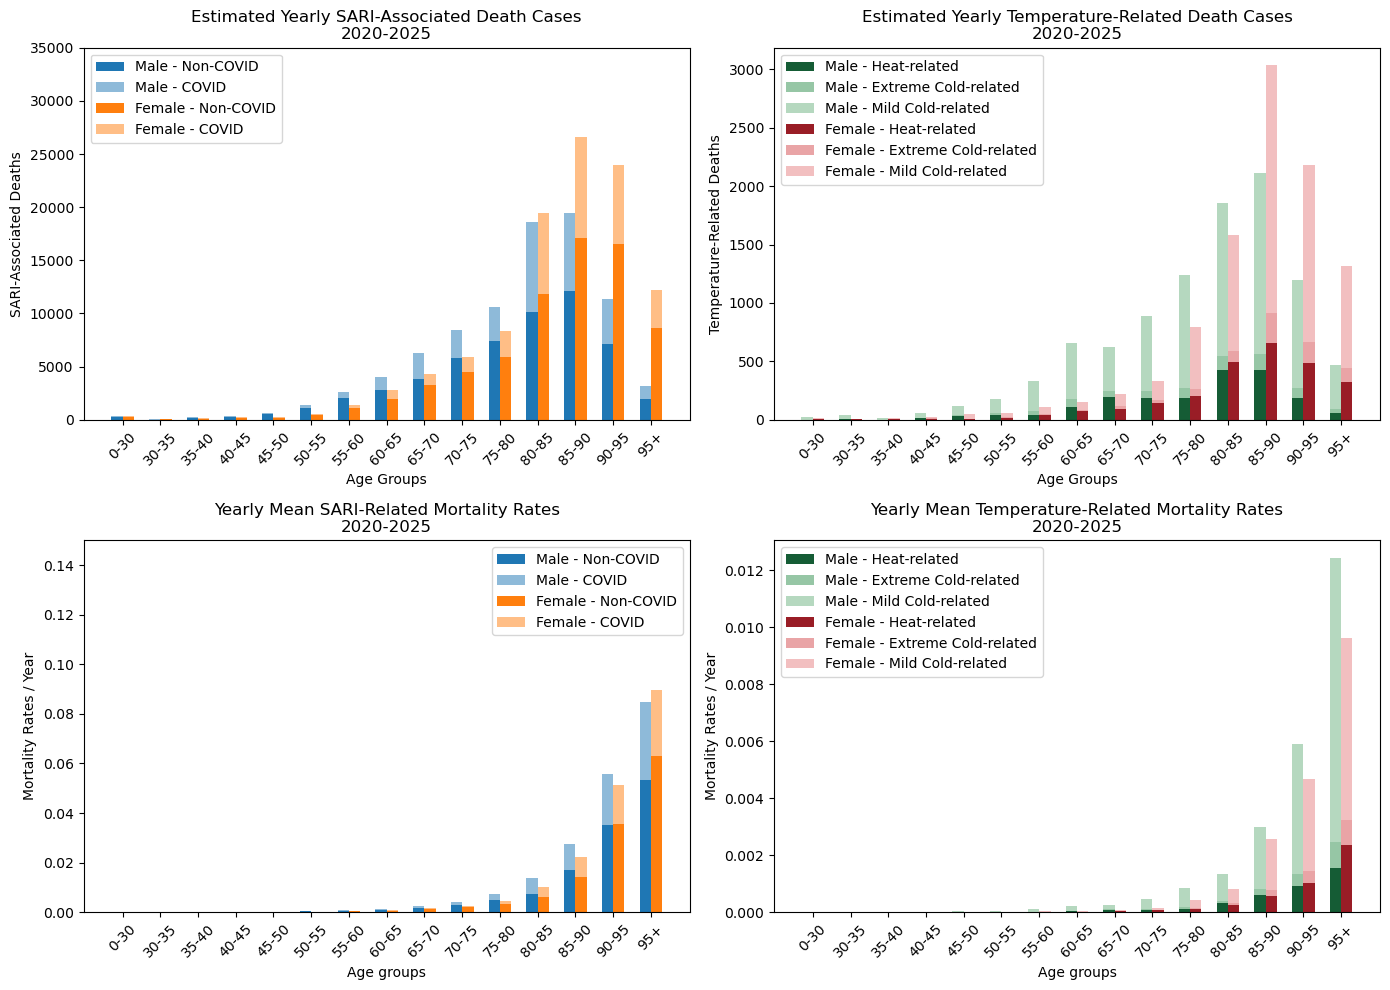

In [6]:
from matplotlib import colormaps
mask = dates.year >= 2020
n_years = dates[mask].year.nunique()
tmp1 = estimates["Non-COVID SARI"][mask].sum(dim=0)
tmp2 = estimates["COVID-19 SARI"][mask].sum(dim=0)
tmp4 = estimates["Heat above 20 °C"][mask].sum(dim=0)
tmp3 = estimates["Cold below 0 °C"][mask].sum(dim=0)
mild_cold = estimates["Mild cold (0–10 °C)"][mask].sum(dim=0)

# Data for the plot
large_groups = ['0-30'] + [f'{i}-{i+5}' for i in range(30, 95, 5)] + ['95+']
small_groups = ['Male', 'Female']

tab10 = colormaps.get_cmap('tab10')
# Use adjacent shades for the cold components and a darker shade for heat.
extreme_cold_colors = ("#96c6a5", "#e9a4a6")
mild_cold_colors = ("#b5d8bf", "#f2bfc0")
heat_colors = ("#155c35", "#991d26")
n_large_groups = len(large_groups)
n_small_groups = len(small_groups)

# Bar width
bar_width = 0.3

# X positions for the groups
x = np.arange(n_large_groups)

# Create the plot
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for i, subgroup in enumerate(small_groups):
    # Bottom values for stacking
    bottoms = np.zeros(15)

    ax[0][0].bar(
        x + i * bar_width,                # Adjust positions for each subgroup
        tmp1[:, i] / n_years,          # Heights of the stack layers
        bar_width,                       # Width of the bars
        bottom=bottoms,                  # Previous layer's heights
        label=f"{subgroup} - Non-COVID" ,  # Label only for the first group
        color=tab10.colors[i]
    )
    ax[0][0].bar(
        x + i * bar_width,                # Adjust positions for each subgroup
        tmp2[:, i] / n_years,          # Heights of the stack layers
        bar_width,                       # Width of the bars
        bottom=tmp1[:, i] / n_years,                  # Previous layer's heights
        label=f"{subgroup} - COVID",  # Label only for the first group
        color=tab10.colors[i],
        alpha = 0.5
    )
    denominator = n_years
    heat = tmp4[:, i] / denominator
    extreme_cold = tmp3[:, i] / denominator
    mild = mild_cold[:, i] / denominator
    ax[0][1].bar(x + i * bar_width, heat, bar_width,
                label=f"{subgroup} - Heat-related", color=heat_colors[i])
    ax[0][1].bar(x + i * bar_width, extreme_cold, bar_width, bottom=heat,
                label=f"{subgroup} - Extreme Cold-related", color=extreme_cold_colors[i])
    ax[0][1].bar(x + i * bar_width, mild, bar_width, bottom=heat + extreme_cold,
                label=f"{subgroup} - Mild Cold-related", color=mild_cold_colors[i])

# Customize the plot
ax[0][0].set_xlabel('Age Groups')
ax[0][0].set_ylabel('SARI-Associated Deaths')
ax[0][0].set_title('Estimated Yearly SARI-Associated Death Cases\n2020-2025')
ax[0][0].set_xticks(x + bar_width / 2)  # Center the ticks for the grouped bars
ax[0][0].set_xticklabels(large_groups)
ax[0][0].tick_params(axis='x', labelrotation=45)
ax[0][0].legend()

ax[0][1].set_xlabel('Age Groups')
ax[0][1].set_ylabel('Temperature-Related Deaths')
ax[0][1].set_title('Estimated Yearly Temperature-Related Death Cases\n2020-2025')
ax[0][1].set_xticks(x + bar_width / 2)  # Center the ticks for the grouped bars
ax[0][1].set_xticklabels(large_groups)
ax[0][1].tick_params(axis='x', labelrotation=45)
ax[0][1].legend()

pop = estimates["Population"][mask].mean(dim=0)

# Create the plot
for i, subgroup in enumerate(small_groups):
    # Bottom values for stacking
    bottoms = np.zeros(15)

    ax[1][0].bar(
        x + i * bar_width,                # Adjust positions for each subgroup
        tmp1[:, i] / pop[:, i] / n_years,          # Heights of the stack layers
        bar_width,                       # Width of the bars
        bottom=bottoms,                  # Previous layer's heights
        label=f"{subgroup} - Non-COVID" ,  # Label only for the first group
        color=tab10.colors[i]
    )
    ax[1][0].bar(
        x + i * bar_width,                # Adjust positions for each subgroup
        tmp2[:, i]  / pop[:, i] / n_years,          # Heights of the stack layers
        bar_width,                       # Width of the bars
        bottom=tmp1[:, i]  / pop[:, i] / n_years,                  # Previous layer's heights
        label=f"{subgroup} - COVID",  # Label only for the first group
        color=tab10.colors[i],
        alpha = 0.5
    )
    denominator = pop[:, i] * n_years
    heat = tmp4[:, i] / denominator
    extreme_cold = tmp3[:, i] / denominator
    mild = mild_cold[:, i] / denominator
    ax[1][1].bar(x + i * bar_width, heat, bar_width,
                label=f"{subgroup} - Heat-related", color=heat_colors[i])
    ax[1][1].bar(x + i * bar_width, extreme_cold, bar_width, bottom=heat,
                label=f"{subgroup} - Extreme Cold-related", color=extreme_cold_colors[i])
    ax[1][1].bar(x + i * bar_width, mild, bar_width, bottom=heat + extreme_cold,
                label=f"{subgroup} - Mild Cold-related", color=mild_cold_colors[i])

# Customize the plot
ax[1][0].set_xlabel('Age groups')
ax[1][0].set_ylabel('Mortality Rates / Year')
ax[1][0].set_title('Yearly Mean SARI-Related Mortality Rates\n2020-2025')
ax[1][0].set_xticks(x + bar_width / 2)  # Center the ticks for the grouped bars
ax[1][0].set_xticklabels(large_groups)
ax[1][0].legend()
ax[1][0].tick_params(axis='x', labelrotation=45)

ax[1][1].set_xlabel('Age groups')
ax[1][1].set_ylabel('Mortality Rates / Year')
ax[1][1].set_title('Yearly Mean Temperature-Related Mortality Rates\n2020-2025')
ax[1][1].set_xticks(x + bar_width / 2)  # Center the ticks for the grouped bars
ax[1][1].set_xticklabels(large_groups)
ax[1][1].legend()
ax[1][1].tick_params(axis='x', labelrotation=45)

ax[0][0].set_ylim(0, 35000)
ax[0][1].set_ylim(0, max(1500, 1.05 * ((tmp3 + mild_cold + tmp4) / n_years).max().item()))
ax[1][0].set_ylim(0, 0.15)
ax[1][1].set_ylim(0, max(0.005, 1.05 * ((tmp3 + mild_cold + tmp4) / pop / n_years).max().item()))

# ax2 = ax[1].twinx()

# ax2.plot(np.arange(2,15), (tmp2[:, 0] / (tmp1[:, 0] + tmp2[:, 0]))[2:], label='M - COVID / all SARI Deaths')
# ax2.plot(np.arange(2,15), (tmp2[:, 1] / (tmp1[:, 1] + tmp2[:, 1]))[2:], label='F - COVID / all SARI Deaths')
# ax2.set_ylabel("ratio of COVID-deaths")

handles1, labels1 = ax[0][0].get_legend_handles_labels()  # Bars legend
# handles2, labels2 = ax2.get_legend_handles_labels()    # Lines legend

# Combine both legends into one
# ax[1].legend(handles1 + handles2, labels1 + labels2, loc='upper left')


# Show the plot
plt.tight_layout()
# plt.show()
# plt.savefig('mortality_age_structure_2.png', bbox_inches='tight', dpi=300)

## Sensitivity to random initialization

Report the mean, minimum and maximum of the member-level daily national RMSE values over the full manuscript period. This reuses the predictions from the same 50 nine-day hybrid members used for Figures 1 and 4.

In [7]:
registered = estimates["Observed"]
rmse_by_member = (members["Predicted national"] - registered).square().mean(dim=1).sqrt()
member_rmse = pd.Series(
    rmse_by_member.numpy(),
    index=pd.Index([path.stem.removeprefix("final_") for path in paths], name="Member"),
    name="Daily RMSE (deaths/day)",
)
initialization_rmse_summary = member_rmse.agg(["mean", "min", "max"])
display(initialization_rmse_summary.round(2))
print(
    f"Mean RMSE across {len(member_rmse)} members: "
    f"{initialization_rmse_summary['mean']:.1f} deaths/day "
    f"(range: {initialization_rmse_summary['min']:.1f}–"
    f"{initialization_rmse_summary['max']:.1f})."
)

mean    81.139999
min     80.169998
max     81.639999
Name: Daily RMSE (deaths/day), dtype: float32

Mean RMSE across 50 members: 81.1 deaths/day (range: 80.2–81.6).


## Numbers for the revised manuscript and reviewer response

In [8]:
annual_components = pd.DataFrame({
    "Registered": estimates["Observed"].numpy(),
    **{name: estimates[name].sum(dim=(1, 2)).numpy() for name in (
        "Heat above 20 °C", "Cold below 10 °C", "Cold below 0 °C",
        "Mild cold (0–10 °C)", "Non-COVID SARI", "COVID-19 SARI",
    )},
}, index=dates).groupby(dates.year).sum().loc[2015:2025]
annual_components["All SARI"] = annual_components["Non-COVID SARI"] + annual_components["COVID-19 SARI"]
for name in ("All SARI", "Heat above 20 °C"):
    annual_components[f"{name} (% of registered)"] = 100 * annual_components[name] / annual_components["Registered"]
display(annual_components.round(2))
display(annual_components[["Heat above 20 °C", "Cold below 10 °C",
                           "Mild cold (0–10 °C)", "Cold below 0 °C"]].sum())

# Age 70 starts at index 9 in the 15-group population and mortality arrays.
age_share = {}
for name in ("Non-COVID SARI", "COVID-19 SARI", "Heat above 20 °C", "Cold below 10 °C"):
    counts = estimates[name][dates.year >= 2020].sum(dim=(0, 2))
    age_share[name] = (100 * counts[9:].sum() / counts.sum()).item()
display(pd.Series(age_share, name="Share at ages 70+ (%)"))

# Compare cold counts with identical weather channels and attribution thresholds.
comparison_days = dates.year >= 2015
years = dates[comparison_days].year.nunique()
cold_hybrid = members["Cold below 10 °C"][:, comparison_days].sum(dim=(1, 2, 3)) / years

def cold_summary(workspace, result):
    factual = result.predictions.total_deaths[comparison_days].sum()
    counterfactual = result.scenarios["cold_10"][comparison_days].sum()
    return {"cold": (factual - counterfactual) / years}

del inference_model
weather_paths = checkpoints["no_disease"]
inputs = load_run_config(weather_paths[0].parents[1] / "config.yaml").data_config
weather_inference = InferenceModel.from_checkpoint(
    weather_paths[0], data_config=inputs, period=ANALYSIS_PERIOD, device=DEVICE,
)
cold_weather = ensemble(
    weather_inference, weather_paths, cold_summary,
    scenarios={"cold_10": {"minimum_c": 10}}, keep_members=True,
)["cold"]
display(pd.DataFrame({
    "Mean annual cold-associated deaths": [cold_hybrid.mean().item(), cold_weather.mean().item()],
    "Between-member SD": [cold_hybrid.std().item(), cold_weather.std().item()],
}, index=["Hybrid", "Weather only (air temperature + dew point)"]))
print(f"Hybrid reduction: {(100 * (1 - cold_hybrid.mean() / cold_weather.mean())).item():.1f}%")

,Registered,Heat above 20 °C,Cold below 10 °C,Cold below 0 °C,Mild cold (0–10 °C),Non-COVID SARI,COVID-19 SARI,All SARI,All SARI (% of registered),Heat above 20 °C (% of registered)
Date,,,,,,,,,,
2015,9.252000e+05,7685.330078,13534.230469,868.710022,12665.519531,147940.078125,0.000000,147940.078125,15.990000,0.83
2016,9.108991e+05,3095.419922,16500.439453,1936.609985,14563.820312,128974.257812,0.000000,128974.257812,14.160000,0.34
2017,9.322631e+05,2542.860107,17067.710938,2941.280029,14126.429688,155653.906250,0.000000,155653.906250,16.700001,0.27
2018,9.548740e+05,9167.150391,17285.320312,2857.479980,14427.839844,162338.312500,0.000000,162338.312500,17.000000,0.96
2019,9.395200e+05,7291.120117,13833.580078,1124.680054,12708.900391,147607.546875,0.000000,147607.546875,15.710000,0.78
2020,9.855720e+05,5400.459961,13399.059570,368.540009,13030.519531,116619.062500,52675.320312,169294.375000,17.180000,0.55
2021,1.023687e+06,2609.179932,20160.519531,3102.570068,17057.949219,83632.476562,111117.757812,194750.234375,19.020000,0.25
2022,1.066341e+06,5369.080078,15237.059570,1771.589966,13465.469727,105574.429688,103221.117188,208795.562500,19.580000,0.50
2023,1.028206e+06,4674.100098,14810.419922,1029.729980,13780.690430,126239.367188,72100.796875,198340.156250,19.290001,0.45


Heat above 20 °C        56775.195312
Cold below 10 °C       169143.765625
Mild cold (0–10 °C)    150380.671875
Cold below 0 °C         18763.109375
dtype: float32

Non-COVID SARI      85.523964
COVID-19 SARI       88.847702
Heat above 20 °C    83.758034
Cold below 10 °C    87.306068
Name: Share at ages 70+ (%), dtype: float64

,Mean annual cold-associated deaths,Between-member SD
Hybrid,15376.706055,336.890869
Weather only (air temperature + dew point),50295.511719,159.861206


Hybrid reduction: 69.4%
